In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

def view_image_with_matplotlib(directory, file_name):
    """
    Loads and displays an image using the Matplotlib library.

    :param directory: The directory containing the image.
    :param file_name: The name of the image file.
    """
    image_path = os.path.join(directory, file_name)

    try:
        image = mpimg.imread(image_path)
        plt.imshow(image)
        plt.axis('off')  # Turn off axis
        plt.show()
    except FileNotFoundError:
        print(f"File not found: {image_path}")
    except Exception as e:
        print(f"An error occurred: {e}")


In [ ]:
import scipy.io

def load_and_view_mat(file_path):
    """
    Function to load and view contents of a .mat file.

    :param file_path: str, path to the .mat file
    """
    # Load the .mat file
    mat_data = scipy.io.loadmat(file_path)

    # Display the keys in the loaded .mat file (i.e., the variable names)
    print("Keys in the .mat file:", mat_data.keys())

    # Iterate through and display each variable's shape and content
    for key, value in mat_data.items():
        if key not in ['__header__', '__version__', '__globals__']:  # Skip metadata
            print(f"\nVariable: {key}")
            print(f"Shape: {value.shape}")
            print(f"Data:\n{value}")

    return mat_data

# Usage:
file_path = '/content/drive/MyDrive/Colab Notebooks/hydraulics/raw/B014_1_190.mat'  # Replace with your file path
mat_data = load_and_view_mat(file_path)


Keys in the .mat file: dict_keys(['__header__', '__version__', '__globals__', 'X190_DE_time', 'X190_FE_time', 'X190RPM'])

Variable: X190_DE_time
Shape: (486224, 1)
Data:
[[-0.46354338]
 [-0.47585169]
 [-0.41806523]
 ...
 [-0.06884308]
 [-0.04902462]
 [-0.01648062]]

Variable: X190_FE_time
Shape: (486224, 1)
Data:
[[0.25620182]
 [0.21963091]
 [0.12635455]
 ...
 [0.00123273]
 [0.01109455]
 [0.03266727]]

Variable: X190RPM
Shape: (1, 1)
Data:
[[1772]]


Keys in the .mat file: dict_keys(['__header__', '__version__', '__globals__', 'X123_DE_time', 'X123_FE_time', 'X123RPM'])

Variable: X123_DE_time
Shape: (487384, 1)
Data:
[[-0.04109723]
 [-0.046104  ]
 [-0.02837169]
 ...
 [ 0.07343262]
 [ 0.04819015]
 [ 0.03838523]]

Variable: X123_FE_time
Shape: (487384, 1)
Data:
[[-0.08115455]
 [-0.09759091]
 [-0.08320909]
 ...
 [ 0.02136727]
 [ 0.00472545]
 [-0.01314909]]

Variable: X123RPM
Shape: (1, 1)
Data:
[[1772]]


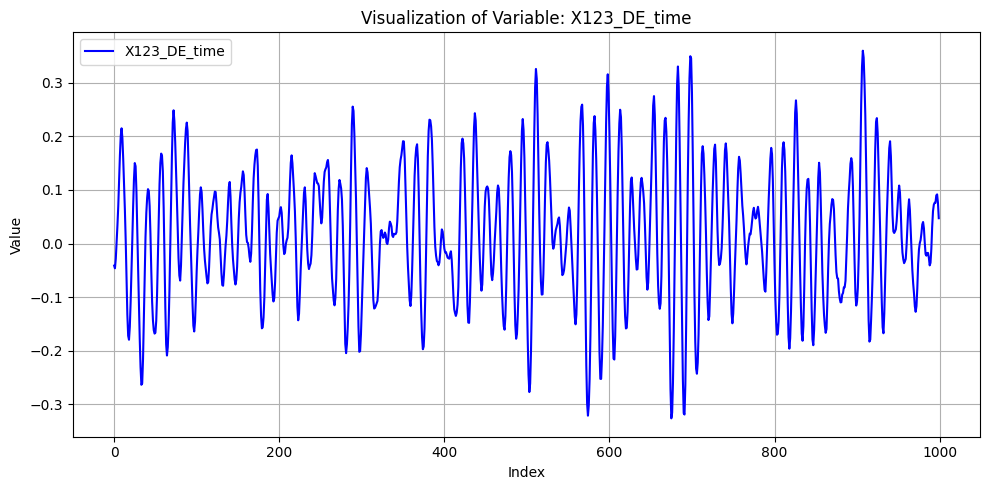

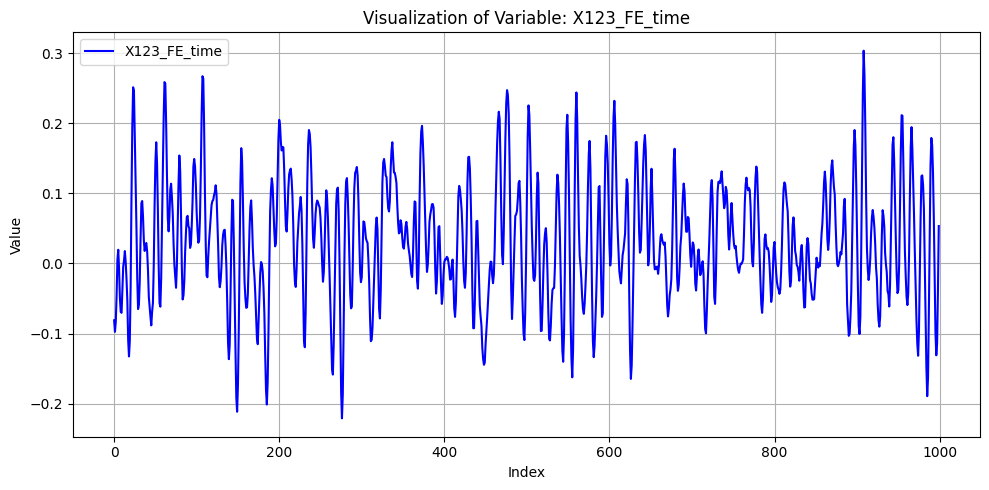

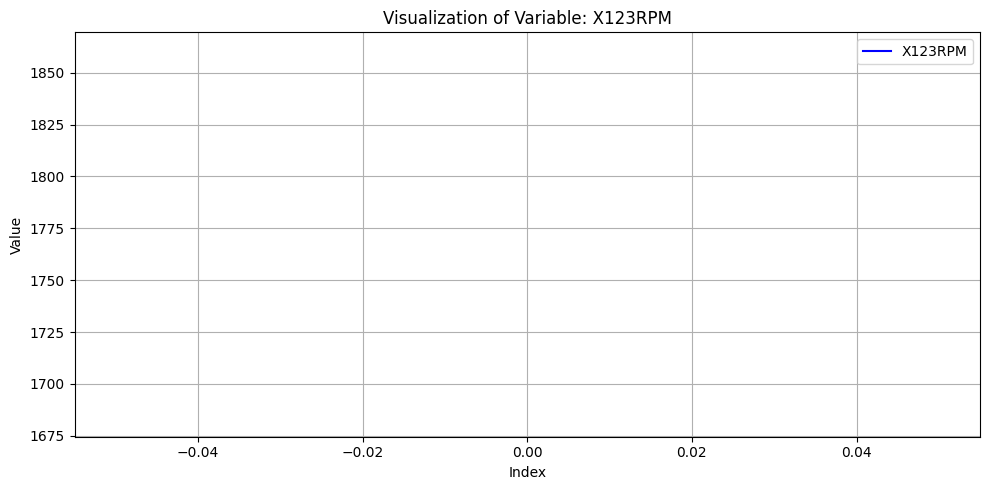

In [ ]:
import scipy.io
import matplotlib.pyplot as plt
import numpy as np


def load_and_view_mat(file_path):
    """
    Function to load, view, and visualize the contents of a .mat file.

    :param file_path: str, path to the .mat file
    """
    # Load the .mat file
    mat_data = scipy.io.loadmat(file_path)

    # Display the keys in the loaded .mat file (i.e., the variable names)
    print("Keys in the .mat file:", mat_data.keys())

    # Iterate through and display each variable's shape and content
    numerical_vars = {}
    for key, value in mat_data.items():
        if key not in ['__header__', '__version__', '__globals__']:  # Skip metadata
            print(f"\nVariable: {key}")
            print(f"Shape: {value.shape}")
            print(f"Data:\n{value}")

            # Collect numerical variables for visualization
            if isinstance(value, np.ndarray):
                numerical_vars[key] = value

    # Visualize numerical variables
    if numerical_vars:
        visualize_variables_separately(numerical_vars)
    else:
        print("\nNo numerical variables found for visualization.")

    return mat_data


def visualize_variables_separately(numerical_vars):
    """
    Visualize each numerical variable from the .mat file on a separate graph.

    :param numerical_vars: dict, dictionary of variable names and their data
    """
    for key, value in numerical_vars.items():
        # Flatten the array if multidimensional and plot a subset for clarity
        data_to_plot = value.flatten()[:1000] if value.ndim > 1 else value[:1000]

        plt.figure(figsize=(10, 5))
        plt.plot(data_to_plot, label=key, color='b')
        plt.title(f"Visualization of Variable: {key}")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


# Usage:
file_path ='/content/drive/MyDrive/Colab Notebooks/hydraulics/raw/B007_1_123.mat'  # Replace with your file path
mat_data = load_and_view_mat(file_path)


In [ ]:
import os
import random
import scipy.io
import matplotlib.pyplot as plt


def load_and_view_random_mat(directory_path):
    """
    Function to randomly select, load, and view the contents of a .mat file from a directory.

    :param directory_path: str, path to the directory containing .mat files
    """
    # Get a list of all .mat files in the directory
    mat_files = [f for f in os.listdir(directory_path) if f.endswith('.mat')]

    if not mat_files:
        print("No .mat files found in the directory.")
        return None, None

    # Randomly select a .mat file
    selected_file = random.choice(mat_files)
    file_path = os.path.join(directory_path, selected_file)

    print(f"Selected file: {selected_file}")

    # Load the .mat file
    mat_data = scipy.io.loadmat(file_path)

    # Display the keys in the loaded .mat file (i.e., the variable names)
    print("Keys in the .mat file:", mat_data.keys())

    # Iterate through and display each variable's shape and content
    for key, value in mat_data.items():
        if key not in ['__header__', '__version__', '__globals__']:  # Skip metadata
            print(f"\nVariable: {key}")
            print(f"Shape: {value.shape}")

    return mat_data, selected_file


def plot_vibration_signals(mat_data):
    """
    Function to plot vibration signals from the loaded .mat data.

    :param mat_data: dict, loaded .mat data
    """
    try:
        # Extract the time-series data from the .mat file
        X123_DE_time = mat_data['X123_DE_time'].flatten()  # Ensure data is 1D
        X123_FE_time = mat_data['X123_FE_time'].flatten()  # Ensure data is 1D

        # Create time axis (since the signals are given as time-domain data, use the indices as time points)
        time_points = range(len(X123_DE_time))  # Use the number of samples as time steps

        # Plot both signals
        plt.figure(figsize=(10, 6))
        plt.subplot(2, 1, 1)
        plt.plot(time_points, X123_DE_time, label="X123_DE_time", color='b')
        plt.title('Vibration Signal - X123_DE_time')
        plt.xlabel('Time Step')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 1, 2)
        plt.plot(time_points, X123_FE_time, label="X123_FE_time", color='r')
        plt.title('Vibration Signal - X123_FE_time')
        plt.xlabel('Time Step')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()

        plt.tight_layout()
        plt.show()
    except KeyError as e:
        print(f"KeyError: {e}. Ensure the expected variables exist in the .mat file.")


# Combined Workflow:
directory_path = '/content/drive/MyDrive/Colab Notebooks/hydraulics/raw/'  # Replace with your directory path
mat_data, selected_file = load_and_view_random_mat(directory_path)

if mat_data:
    print(f"Visualizing data from file: {selected_file}")
    plot_vibration_signals(mat_data)


Selected file: B021_1_227.mat


KeyboardInterrupt: 

{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Fri Jan 28 11:46:29 2000', '__version__': '1.0', '__globals__': [], 'X123_DE_time': array([[-0.04109723],
       [-0.046104  ],
       [-0.02837169],
       ...,
       [ 0.07343262],
       [ 0.04819015],
       [ 0.03838523]]), 'X123_FE_time': array([[-0.08115455],
       [-0.09759091],
       [-0.08320909],
       ...,
       [ 0.02136727],
       [ 0.00472545],
       [-0.01314909]]), 'X123RPM': array([[1772]], dtype=uint16)}
Selected file: IR014_1_175.mat
Keys in the .mat file: dict_keys(['__header__', '__version__', '__globals__', 'X217', 'X217_DE_time', 'X175_DE_time', 'X175_FE_time', 'X175RPM'])

Variable: X217
Shape: (489125, 2)
Data:
[[-0.01968912  0.0463752 ]
 [-0.04995504  0.0398664 ]
 [-0.07407828  0.02367576]
 ...
 [-0.00687492  0.08066844]
 [-0.03278808  0.09022824]
 [-0.05723676  0.08835696]]

Variable: X217_DE_time
Shape: (489125, 1)
Data:
[[0.23782154]
 [0.20444308]
 [0.12141415]
 ...
 [0.41368431]
 [0

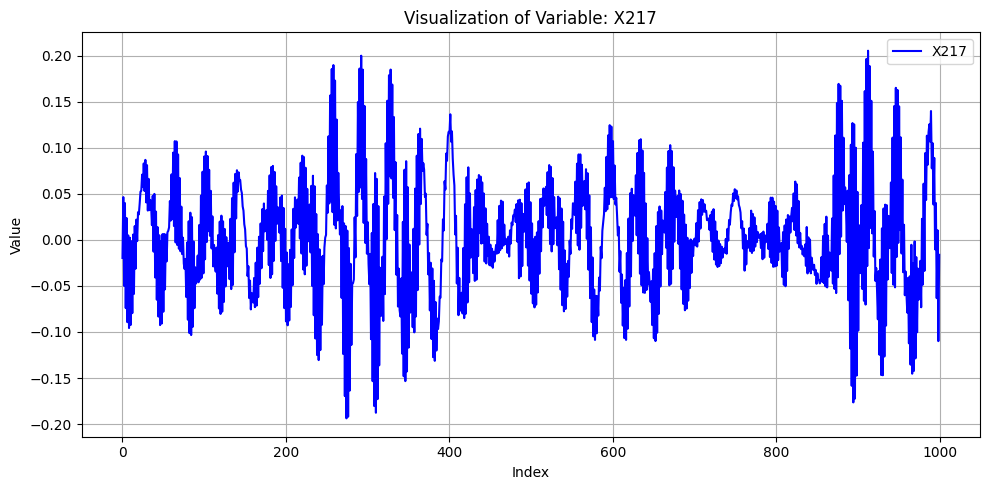

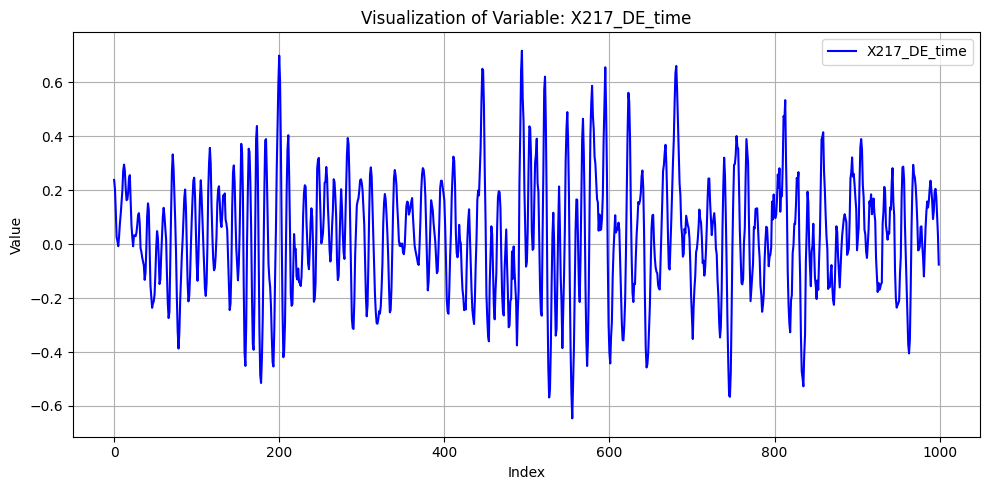

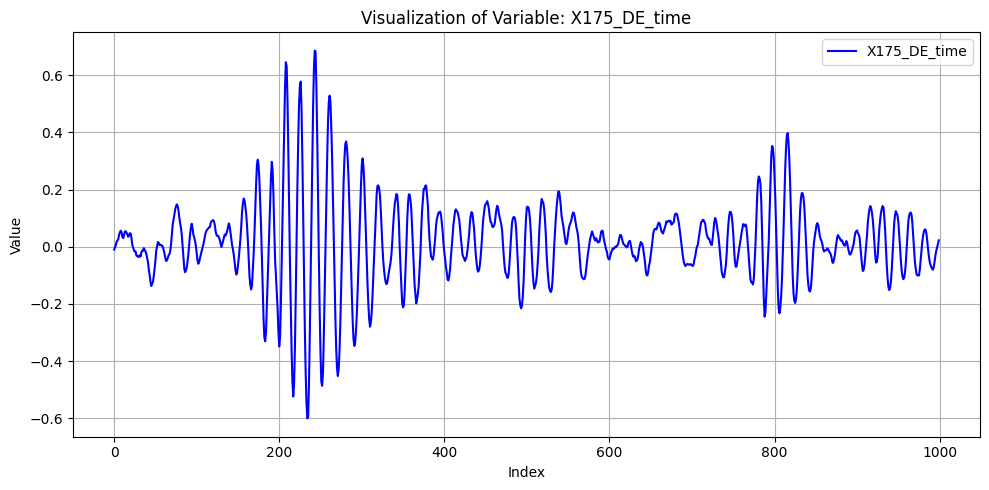

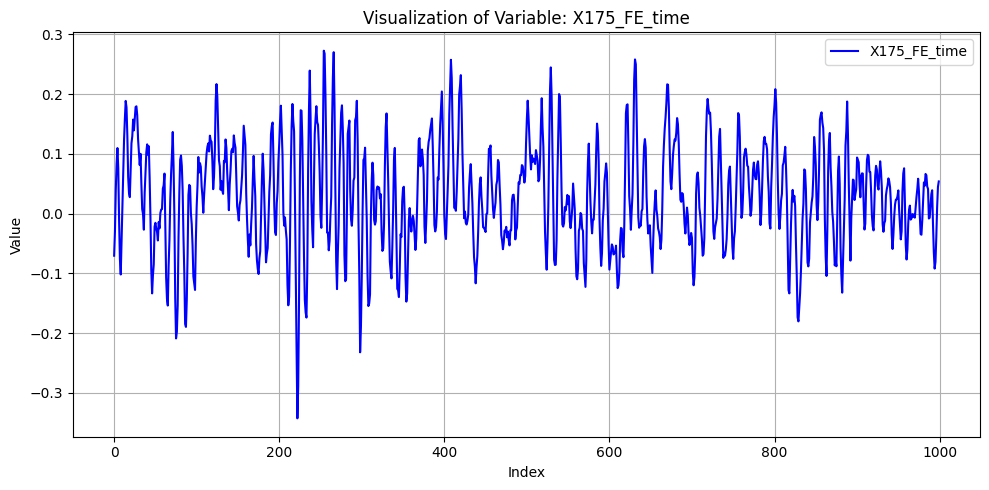

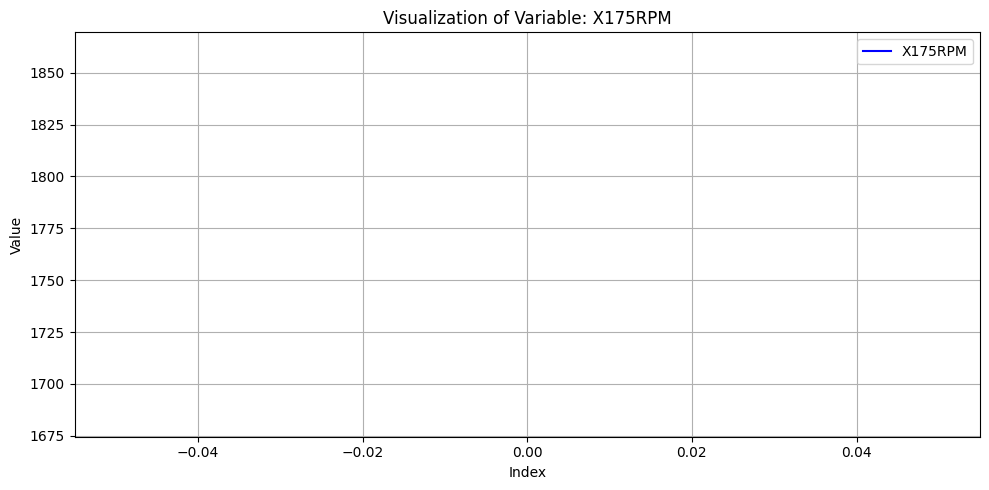

In [ ]:
import os
import random
import scipy.io
import matplotlib.pyplot as plt
import numpy as np

def load_and_view_random_mat(directory_path):
    """
    Function to randomly select, load, and view the contents of a .mat file from a directory.

    :param directory_path: str, path to the directory containing .mat files
    :return: dict, loaded data from the selected .mat file
    """
    # Get a list of all .mat files in the directory
    mat_files = [f for f in os.listdir(directory_path) if f.endswith('.mat')]

    if not mat_files:
        print("No .mat files found in the directory.")
        return None

    # Randomly select a .mat file
    selected_file = random.choice(mat_files)
    file_path = os.path.join(directory_path, selected_file)

    print(f"Selected file: {selected_file}")

    # Load the .mat file
    mat_data = scipy.io.loadmat(file_path)

    # Display the keys in the loaded .mat file (i.e., the variable names)
    print("Keys in the .mat file:", mat_data.keys())

    # Iterate through and display each variable's shape and content
    for key, value in mat_data.items():
        if key not in ['__header__', '__version__', '__globals__']:  # Skip metadata
            print(f"\nVariable: {key}")
            print(f"Shape: {value.shape}")
            print(f"Data:\n{value}")

    return mat_data


def visualize_variables_separately(mat_data):
    """
    Visualize each numerical variable from the .mat file on a separate graph.

    :param mat_data: dict, loaded data from the .mat file
    """
    numerical_vars = {}
    for key, value in mat_data.items():
        if isinstance(value, np.ndarray):
            numerical_vars[key] = value

    if not numerical_vars:
        print("\nNo numerical variables found for visualization.")
        return

    for key, value in numerical_vars.items():
        # Flatten the array if multidimensional and plot a subset for clarity
        data_to_plot = value.flatten()[:1000] if value.ndim > 1 else value[:1000]

        plt.figure(figsize=(10, 5))
        plt.plot(data_to_plot, label=key, color='b')
        plt.title(f"Visualization of Variable: {key}")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


# Usage
directory_path = '/content/drive/MyDrive/Colab Notebooks/hydraulics/raw/'  # Replace with your directory path
print(mat_data)
mat_data = load_and_view_random_mat(directory_path)

# Visualize if data was successfully loaded
if mat_data:
    visualize_variables_separately(mat_data)


In [ ]:
import numpy as np

# Create some example arrays
arr1 = np.array([1, 2, 3])
arr2 = np.array([[4, 5, 6], [7, 8, 9]])

# Save arrays into an NPZ file
np.savez("example.npz", array1=arr1, array2=arr2)


# Load the NPZ file
data = np.load("/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz")
print(data)

# Access arrays by their names



NpzFile '/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz' with keys: data, labels


In [ ]:
import numpy as np

file_path = "/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz"
data = np.load(file_path)

# Display the keys stored in the file
print("Keys in NPZ file:", data.keys())


Keys in NPZ file: KeysView(NpzFile '/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz' with keys: data, labels)


In [ ]:
import numpy as np

# Load the .npz file
file_path = "/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz"
data = np.load(file_path)

# Check the keys
print("Keys in NPZ file:", data.keys())

# Load the image data and labels
images = data['data']
labels = data['labels']

# Print the shapes of the data and labels
print(f"Shape of the image data: {images.shape}")
print(f"Shape of the labels: {labels.shape}")


Keys in NPZ file: KeysView(NpzFile '/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz' with keys: data, labels)
Shape of the image data: (4600, 32, 32)
Shape of the labels: (4600,)


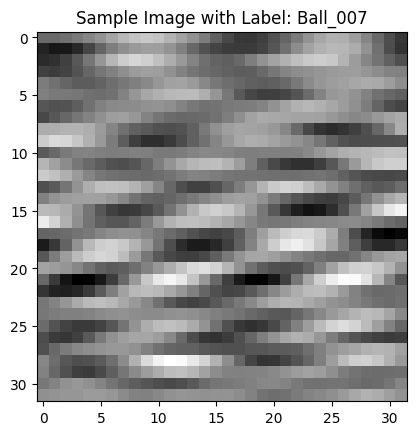

In [ ]:
import matplotlib.pyplot as plt

# Display the first image
plt.imshow(images[0], cmap='gray')  # Use 'gray' for grayscale images
plt.title(f"Sample Image with Label: {labels[0]}")
plt.show()


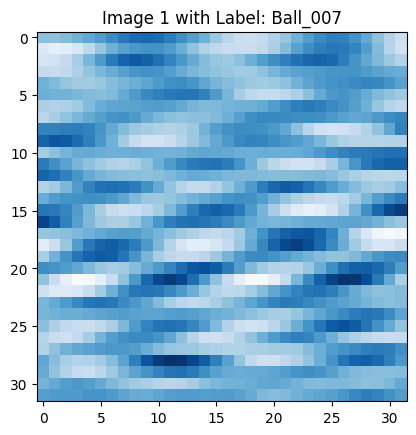

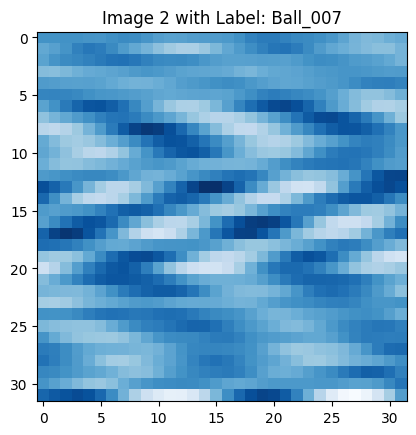

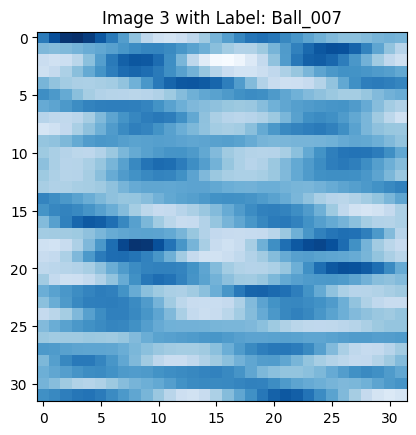

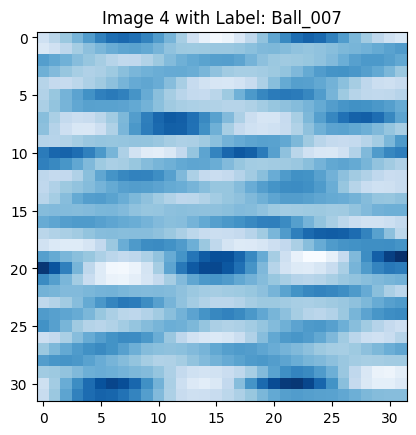

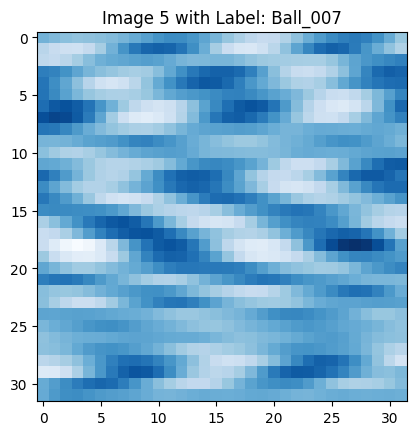

In [ ]:
# Display the first 5 images
for i in range(5):
    plt.figure()
    plt.imshow(images[i], cmap='Blues')
    plt.title(f"Image {i + 1} with Label: {labels[i]}")
    plt.show()


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Load the data from the .npz file
file_path = "/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz"
data = np.load(file_path)

# Extract the images and labels
images = data['data']
labels = data['labels']

from sklearn.model_selection import train_test_split

# Split the data into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(images, labels, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Print the shape of the resulting splits
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)


Training set shape: (3220, 32, 32) (3220,)
Validation set shape: (690, 32, 32) (690,)
Test set shape: (690, 32, 32) (690,)


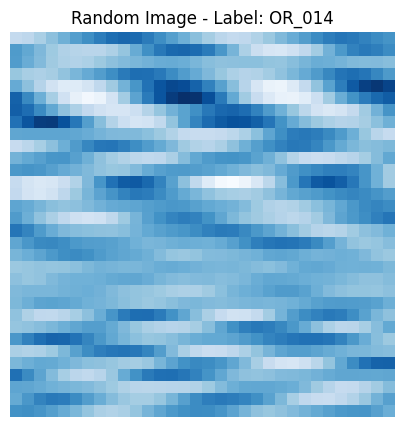

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load the data from the .npz file
file_path = "/content/drive/MyDrive/Colab Notebooks/hydraulics/CWRU_48k_load_1_CNN_data.npz"
data = np.load(file_path)

# Extract the images and labels
images = data['data']

# Generate a random index to select an image
random_index = np.random.randint(0, images.shape[0])

# Display the image using matplotlib
plt.figure(figsize=(5, 5))
plt.imshow(images[random_index], cmap='Blues')  # Display as a blue image
plt.axis('off')
plt.title(f"Random Image - Label: {data['labels'][random_index]}")
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Assuming y_train and y_val are your label arrays
label_encoder = LabelEncoder()

# Fit the encoder on your training labels
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Print the label encoder classes to see the mapping
print("Classes:", label_encoder.classes_)


Classes: ['Ball_007' 'Ball_014' 'Ball_021' 'IR_007' 'IR_014' 'IR_021' 'Normal'
 'OR_007' 'OR_014' 'OR_021']


In [ ]:
# Check data types and verify no non-numeric values remain in the labels
print("y_train dtype:", y_train_encoded.dtype)
print("y_val dtype:", y_val_encoded.dtype)


y_train dtype: int64
y_val dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Assuming y_train and y_val are your label arrays from the npz file
label_encoder = LabelEncoder()

# Fit the encoder on the training labels and transform them
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Verify that the labels are encoded as integers
print("Classes:", label_encoder.classes_)
print("Encoded y_train sample:", y_train_encoded[:5])


Classes: ['Ball_007' 'Ball_014' 'Ball_021' 'IR_007' 'IR_014' 'IR_021' 'Normal'
 'OR_007' 'OR_014' 'OR_021']
Encoded y_train sample: [4 2 3 1 3]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(label_encoder.classes_), activation='softmax')  # Adjust output size to number of classes
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # Suitable for integer-encoded labels
              metrics=['accuracy'])

# Print the model summary to verify
model.summary()


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          65,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,994 (476.54 KB)

 Trainable params: 121,994 (476.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the CNN model
model22 = models.Sequential([
    layers.Conv2D(32, (5, 5), activation='relu', input_shape=(32, 32, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (5, 5), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (5, 5), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(label_encoder.classes_), activation='softmax')  # Adjust output size to number of classes
])

# Compile the model
model22.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # Suitable for integer-encoded labels
              metrics=['accuracy'])

# Print the model summary to verify
model22.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 32)          │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 10, 10, 64)          │          51,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 1, 1, 64)            │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 159,370 (622.54 KB)

 Trainable params: 159,370 (622.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model with the encoded training and validation data
history = model.fit(
    X_train, y_train_encoded,
    epochs=10,  # Adjust as needed
    validation_data=(X_val, y_val_encoded),
    batch_size=32  # Adjust as needed
)


Epoch 1/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.0897 - loss: 2.3031 - val_accuracy: 0.0841 - val_loss: 2.3037
Epoch 2/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.1083 - loss: 2.3023 - val_accuracy: 0.0841 - val_loss: 2.3043
Epoch 3/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.1041 - loss: 2.3024 - val_accuracy: 0.0841 - val_loss: 2.3049
Epoch 4/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.0945 - loss: 2.3021 - val_accuracy: 0.0841 - val_loss: 2.3052
Epoch 5/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.1082 - loss: 2.3023 - val_accuracy: 0.0841 - val_loss: 2.3054
Epoch 6/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.1132 - loss: 2.3015 - val_accuracy: 0.0841 - val_loss: 2.3056
Epoch 7/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.1012 - loss: 2.3023 - val_accuracy: 0.0841 - val_loss: 2.3058
Epoch 8/10
101/101 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.1023 - loss: 2.3022 - val_accu

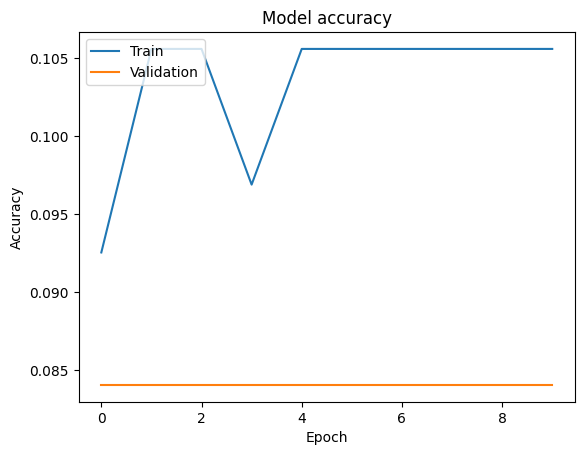

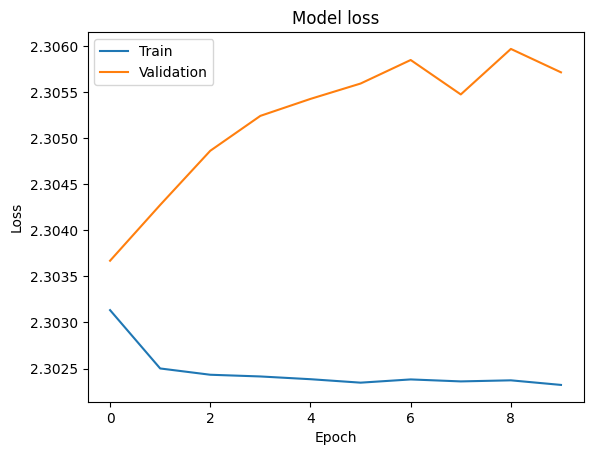

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


In [ ]:
# Calculate accuracy
# Import necessary libraries for metrics and visualization
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score
import numpy as np

accuracy = accuracy_score(y_train_encoded, y_pred_classes)

# Calculate precision and recall (macro averages)
precision = precision_score(y_test_encoded, y_pred_classes, average='macro')
recall = recall_score(y_test_encoded, y_pred_classes, average='macro')

# Print classification report for detailed metrics
report = classification_report(y_test_encoded, y_pred_classes, target_names=label_encoder.classes_)
conf_matrix = confusion_matrix(y_test_encoded, y_pred_classes)

# Display the results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Classification Report:\n", report)
print("Confusion Matrix:\n", conf_matrix)


NameError: name 'y_pred_classes' is not defined

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score

# Assuming y_train, y_val, and y_pred are your label arrays and predictions
label_encoder = LabelEncoder()

# Fit the encoder on your training labels
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Convert predictions to class labels
y_pred_classes = label_encoder.inverse_transform(y_pred)

# Print the label encoder classes to see the mapping
print("Classes:", label_encoder.classes_)

# Calculate metrics
accuracy = accuracy_score(y_val, y_pred_classes)
precision = precision_score(y_val, y_pred_classes, average='weighted')
recall = recall_score(y_val, y_pred_classes, average='weighted')

# Print the metrics
print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')

# Print a classification report for more details
print(classification_report(y_val, y_pred_classes))


NameError: name 'y_pred' is not defined